# 00 · The measurement program, end to end

**One synthetic world, known ground truth, four modules that build on each other.**

A US auto/home insurer spends on TV, Social, Paid Search and two programmatic DSP vendors. Last-touch attribution says
one thing, vendor dashboards say another, and the MMM is uncalibrated. This notebook walks the program in the order a
measurement team would run it:

1. **Social geo holdout** - the first, rough test: county units, locked synthetic control, honest *directional* read.
2. **Paid Search two-arm dark-out** - all-search vs branded-only arms; measures organic **cannibalisation**.
3. **Programmatic DSP** (flagship) - two vendors, two designs (Mahalanobis-matched zip patches; K-means cluster +
   synthetic-control tournament), holdout **sized by its own power analysis on sales**, triangulated readout.
4. **Experiment-calibrated Bayesian MMM** - the tests become likelihood terms; the posterior drives a budget
   reallocation and a *next test* recommendation (value of information).

Every number below is read from `reports/results/*.json`, written by `python -m incrlab.pipeline all`.
Each module has its own deep-dive notebook (`01_meta` ... `04_mmm_calibration`).

In [1]:
import json, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES, FIG = ROOT / "reports" / "results", ROOT / "reports" / "figures"
S = json.loads((RES / "summary.json").read_text())
R = {m: json.loads((RES / f"{m}.json").read_text()) for m in ("meta", "search", "dsp", "mmm")}
gt = json.loads((ROOT / "data" / "ground_truth.json").read_text())

def show(module, name, width=950):
    display(Image(filename=str(FIG / module / f"{name}.png"), width=width))

def pct(x, d=1):
    return "n/a" if x is None else f"{x:+.{d}%}"

print(f"seed {S['seed']} | small={S['small']} | scoreboard coverage {S['scoreboard_coverage']} | generated {S['generated_at']}")

seed 20260 | small=False | scoreboard coverage 14/15 | generated 2026-10-30T19:09:20


## The world and its truth

The simulator generates 156 weeks of national + county + zip panels (two synthetic regions, ~1,100 zips with ACS-like
features), a quote-start -> rated-quote -> sale funnel, adstock + Hill channel responses, biased last-touch and vendor
attribution, and three test windows. The true return of every channel is known:

In [2]:
ch = gt["channels"]
truth = pd.DataFrame({c: {"label": ch[c]["label"], "true ROI": ch[c]["roi"], "true marginal ROI": ch[c]["marginal_roi"],
                          "true cost / incr. sale": ch[c]["cost_per_incremental"]["sales"]} for c in ch}).T
truth.style.format({"true ROI": "{:.2f}", "true marginal ROI": "{:.2f}", "true cost / incr. sale": "${:,.0f}"})

,label,true ROI,true marginal ROI,true cost / incr. sale
tv,TV / Brand,0.45,0.23,"$3,302"
social,Social,1.63,0.95,$923
search_brand,Paid Search - Branded,1.79,0.44,$838
search_nonbrand,Paid Search - Non-branded,1.26,0.51,"$1,189"
dsp_a,Programmatic DSP - Vendor A,3.89,2.15,$386
dsp_b,Programmatic DSP - Vendor B,0.08,0.04,"$18,900"


## 1 · Social geo holdout (first test): rough but correct

County bundles are scored as candidate treatment units; synthetic-control weights are **locked** before launch and validated by
injecting known lifts. The holdout leaks (25% of spend keeps serving) and runs 8 weeks, so the honest label is *directional*.

Treated: **EM-C03+EM-C07** - verdict **directional**. QS contribution +2.7% (truth +4.2%); design MDE 10.1%. Last-touch over-claims incremental quote starts **3.8x**.

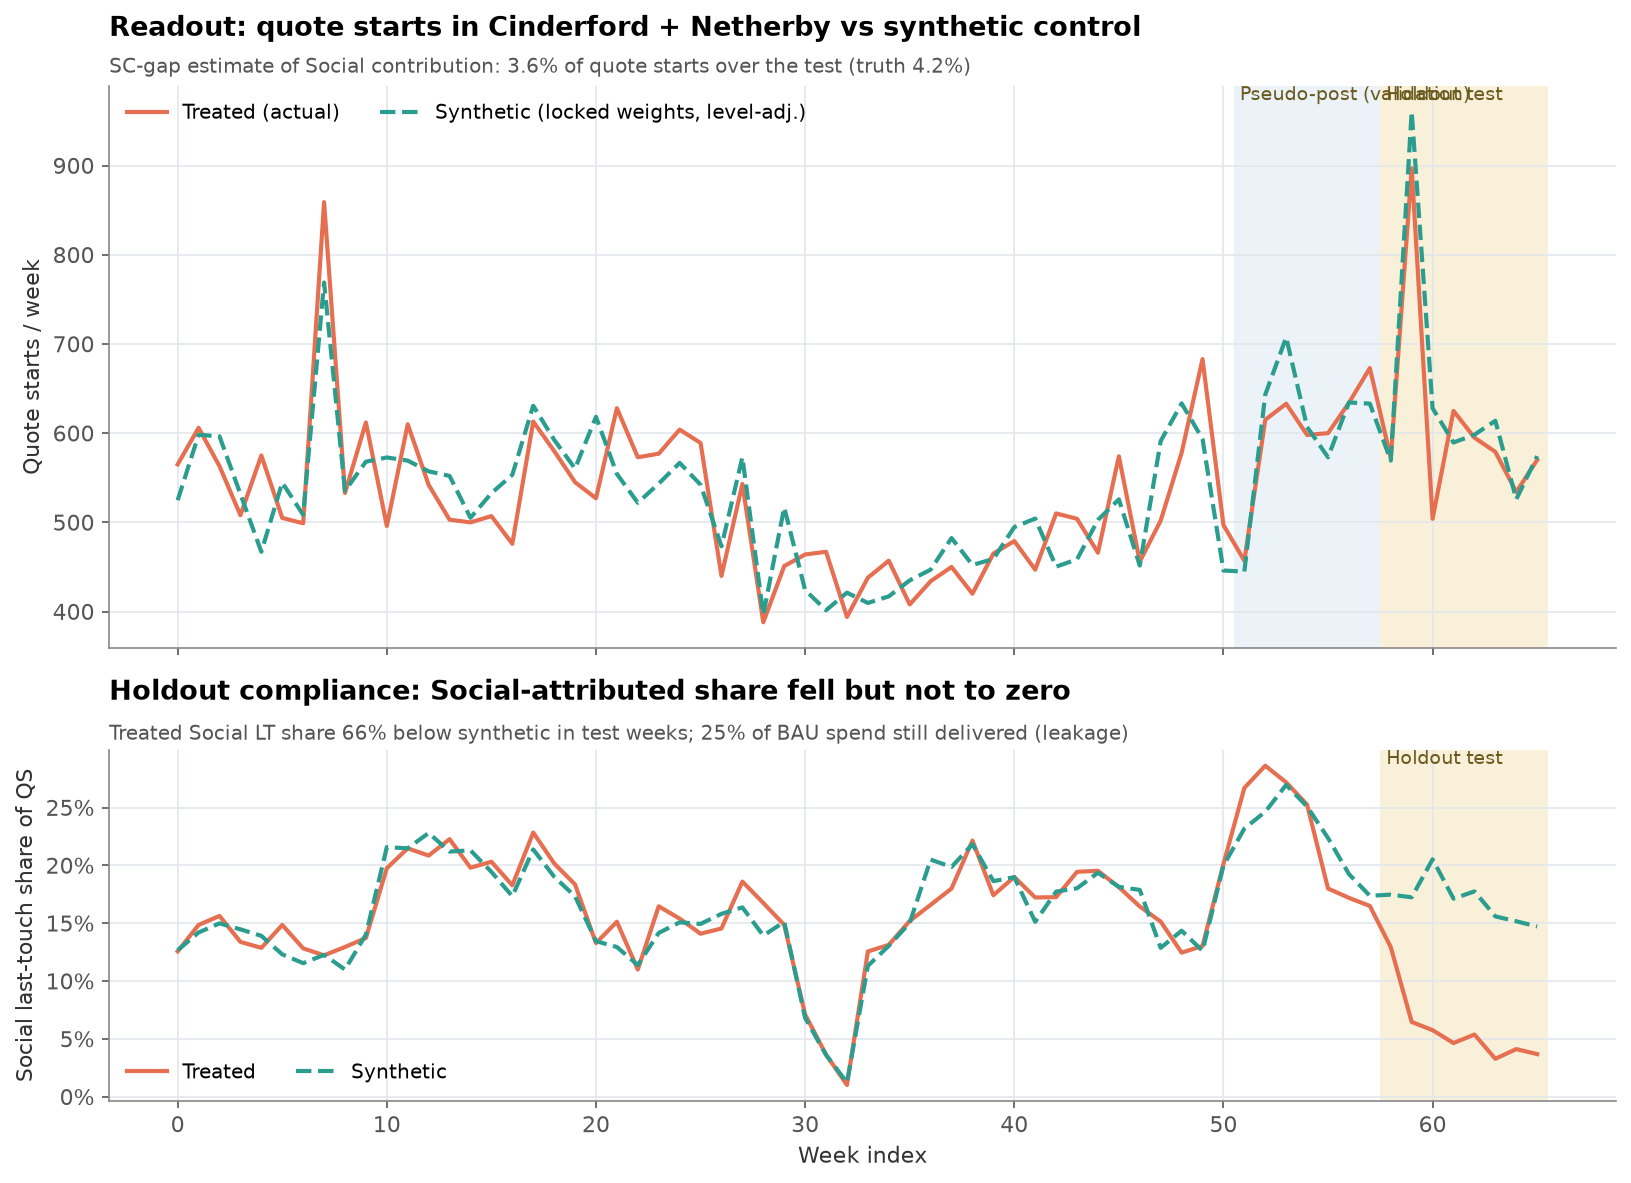

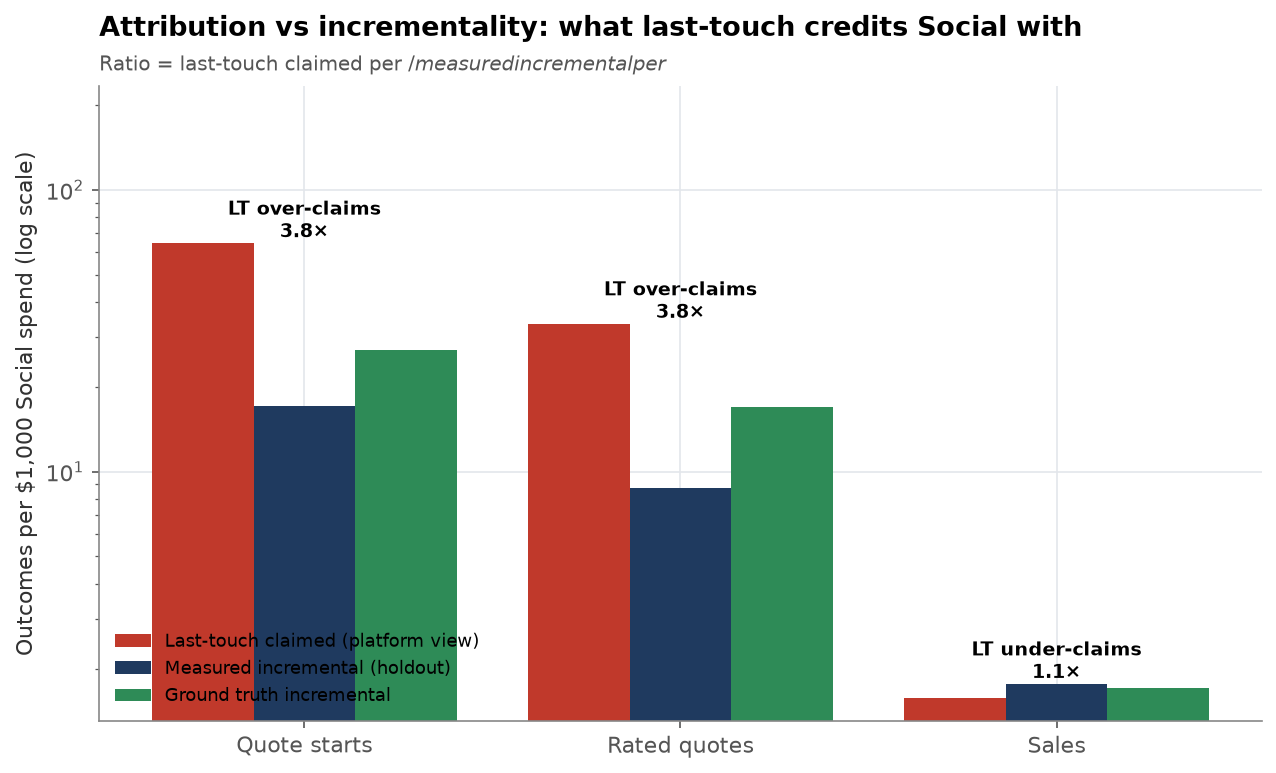

In [3]:
m = S["modules"]["meta"]
display(Markdown(f"Treated: **{m['treated_unit']}** - verdict **{m['verdict']}**. QS contribution {pct(m['lift_qs'])} "
                 f"(truth {pct(m['true_lift_qs'])}); design MDE {m['design_mde']:.1%}. Last-touch over-claims "
                 f"incremental quote starts **{m['lt_overclaim_ratio_qs']:.1f}x**."))
show("meta", "09_readout_treated_vs_synthetic")
show("meta", "13_attribution_vs_incrementality")

## 2 · Paid Search two-arm dark-out: what is really incremental?

Two treatment arms (all paid search paused; branded only paused), a matched control and BAU donors. DiD with unit + week
fixed effects and cluster-robust SE, a BSTS counterfactual, and an organic **recapture** estimate.

Organic recaptures **35%** of lost branded rated quotes (truth 40%). 100% of 20 truth-scored quantities fall inside their 90% intervals. Sales MDE (all-search arm) 30%: rated quotes are decision-grade, sales are not.

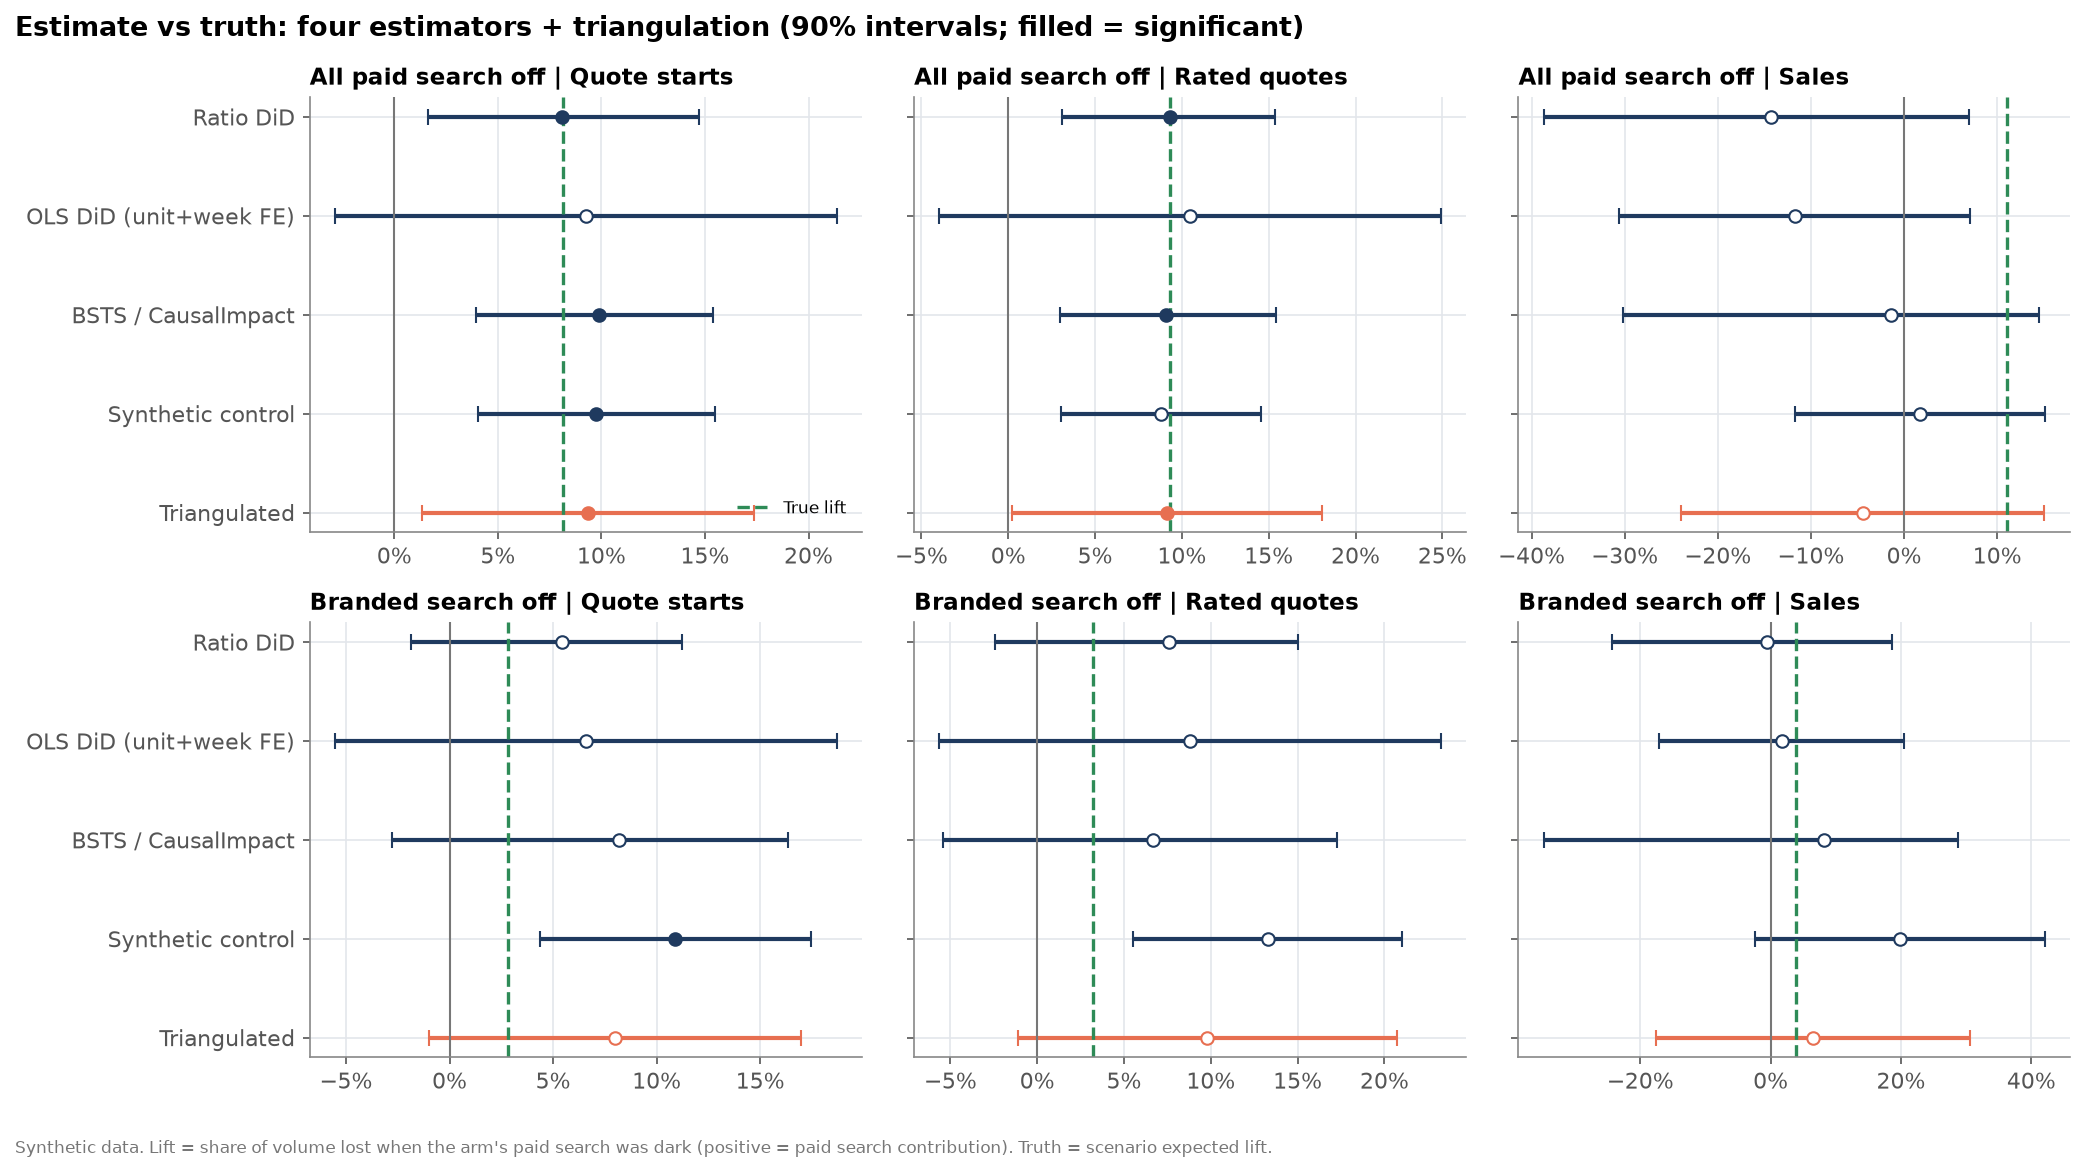

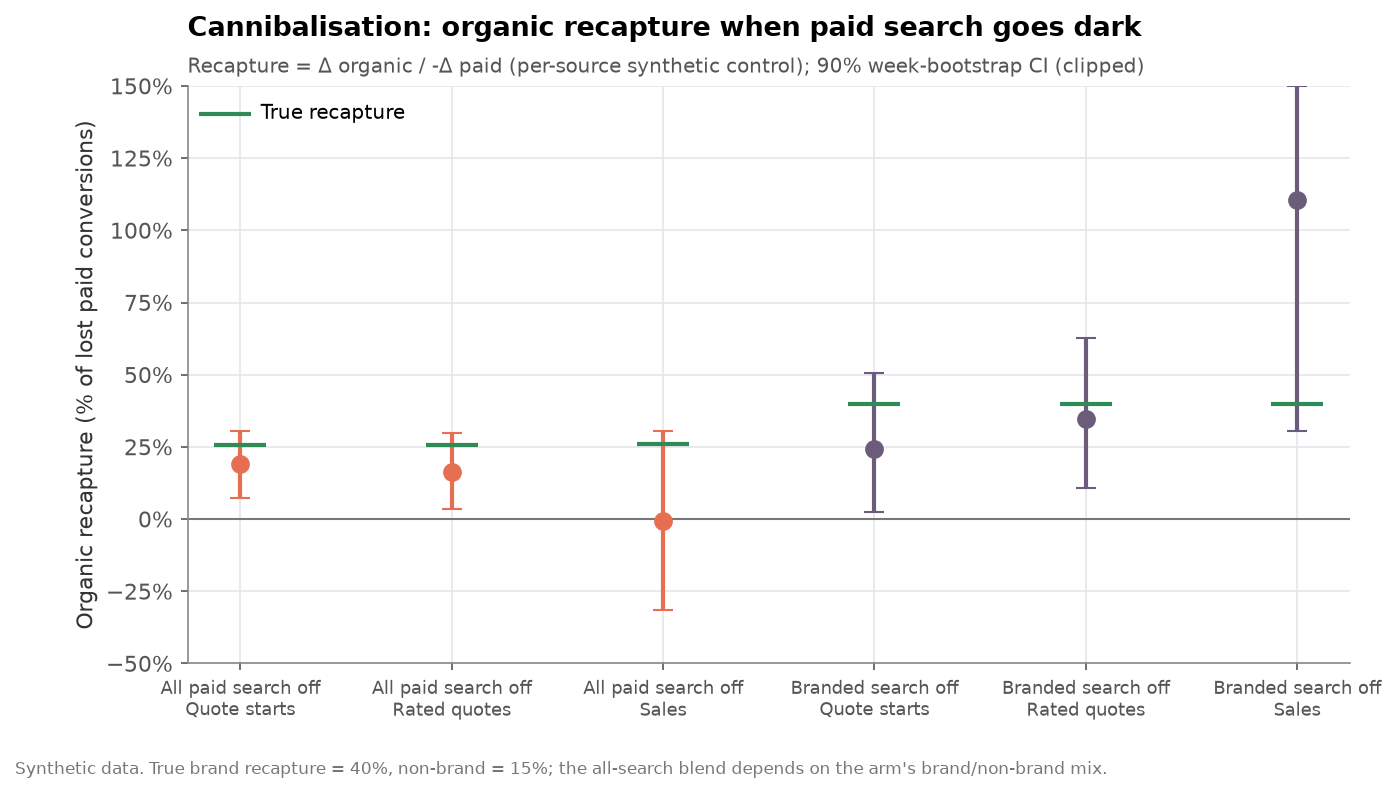

In [4]:
m = S["modules"]["search"]
display(Markdown(f"Organic recaptures **{m['branded_recapture']:.0%}** of lost branded rated quotes (truth "
                 f"{m['branded_true_recapture']:.0%}). {m['share_truth_in_ci']:.0%} of {m['n_truth_rows']} truth-scored "
                 f"quantities fall inside their 90% intervals. Sales MDE (all-search arm) {m['all_search_mde_sales']:.0%}: "
                 "rated quotes are decision-grade, sales are not."))
show("search", "08_forest_truth")
show("search", "11_recapture")

## 3 · Programmatic DSP (flagship): design for the decision metric

The first DSP plan (0.5M-pop patch, 6 weeks) had a ~30% sales MDE and only a relaxed-tier twin; it read the strong
vendor as noise. The v2 design makes **power drive the design**: the module walks a holdout-size ladder on design-window
data and keeps the smallest strict-gate design that detects a **20% sales contribution at 80% power** over 12 weeks.
The decision rule is fixed before launch and hinges on **sales**: a design not powered for sales can at most say *HOLD*.

,pop_target,tier,t_pop,n_strict,patch_id,c_county,mde_qs,mde_rated,mde_sales,meets_target
0,500000,relaxed,495382.0,0,NV-C04:East,Lanternfield County,0.128,0.155,0.217,False
1,750000,strict,781577.0,6,NV-C11:North,Kingsmere County,0.099,0.085,0.219,False
2,1000000,strict,998063.0,2,NV-C11:North,Kingsmere County,0.073,0.071,0.197,True
3,1250000,strict,1236800.0,5,NV-C11:North,Kingsmere County,0.067,0.063,0.178,True


**Vendor A** - POWERED: 1.00M pop, 12 weeks, design sales MDE 19.7% -> **GO** (window ROI 3.78, true 2.36).  
**Vendor B** - design sales MDE 39% -> **HOLD - RE-TEST POWERED ON SALES** (true ROI 0.07: its quote-start lift is real but it barely sells).

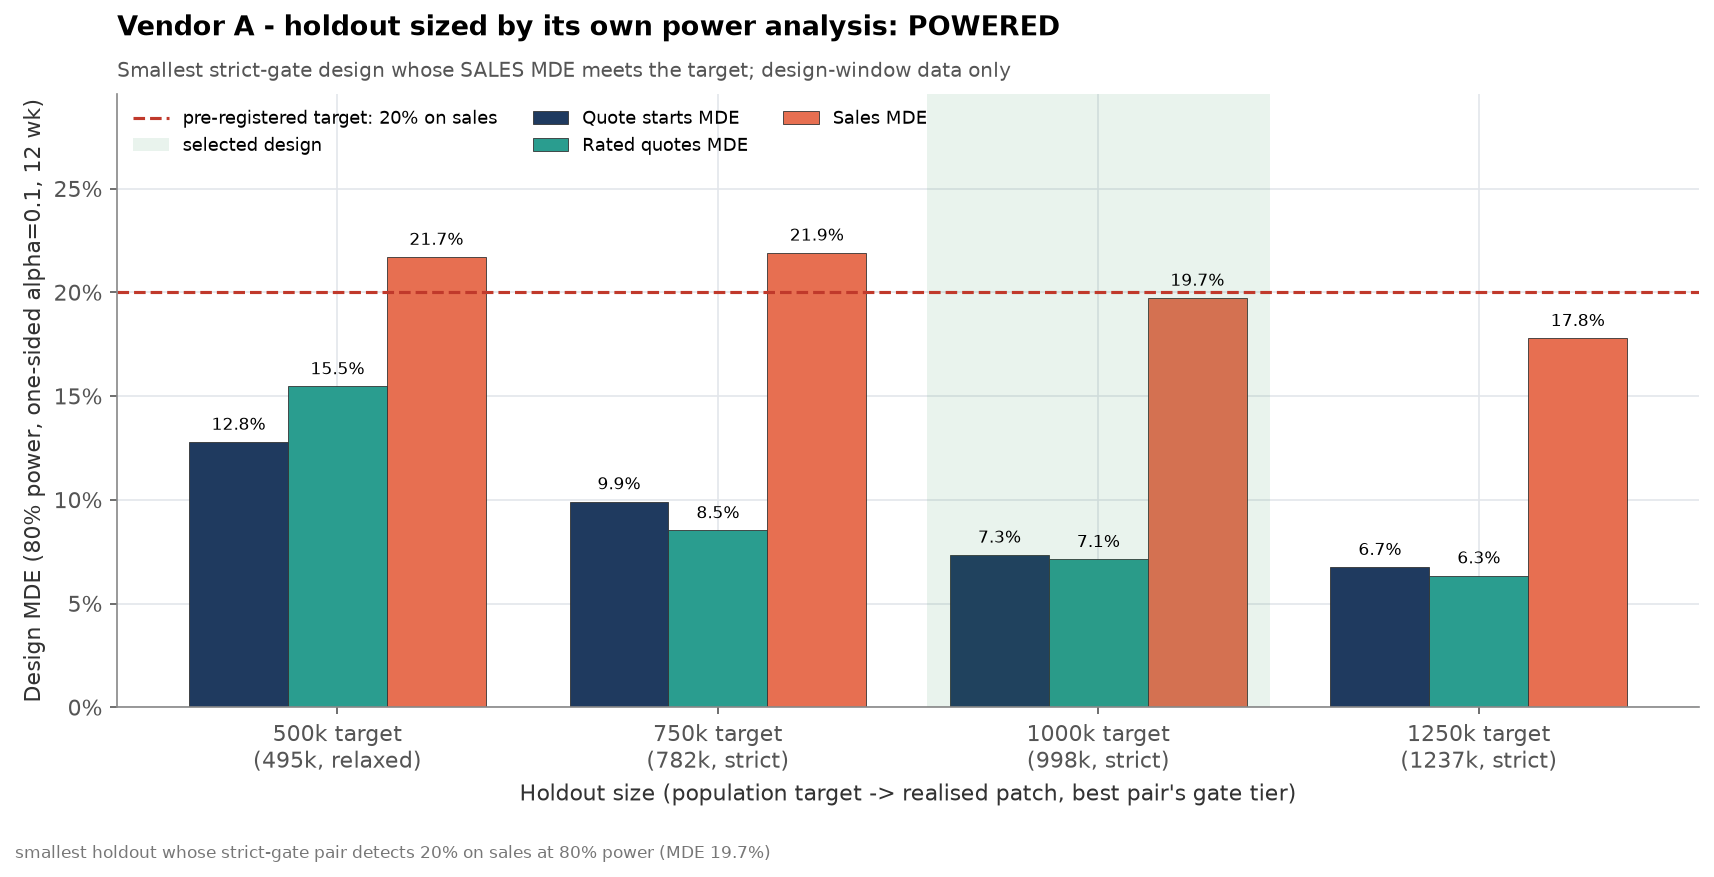

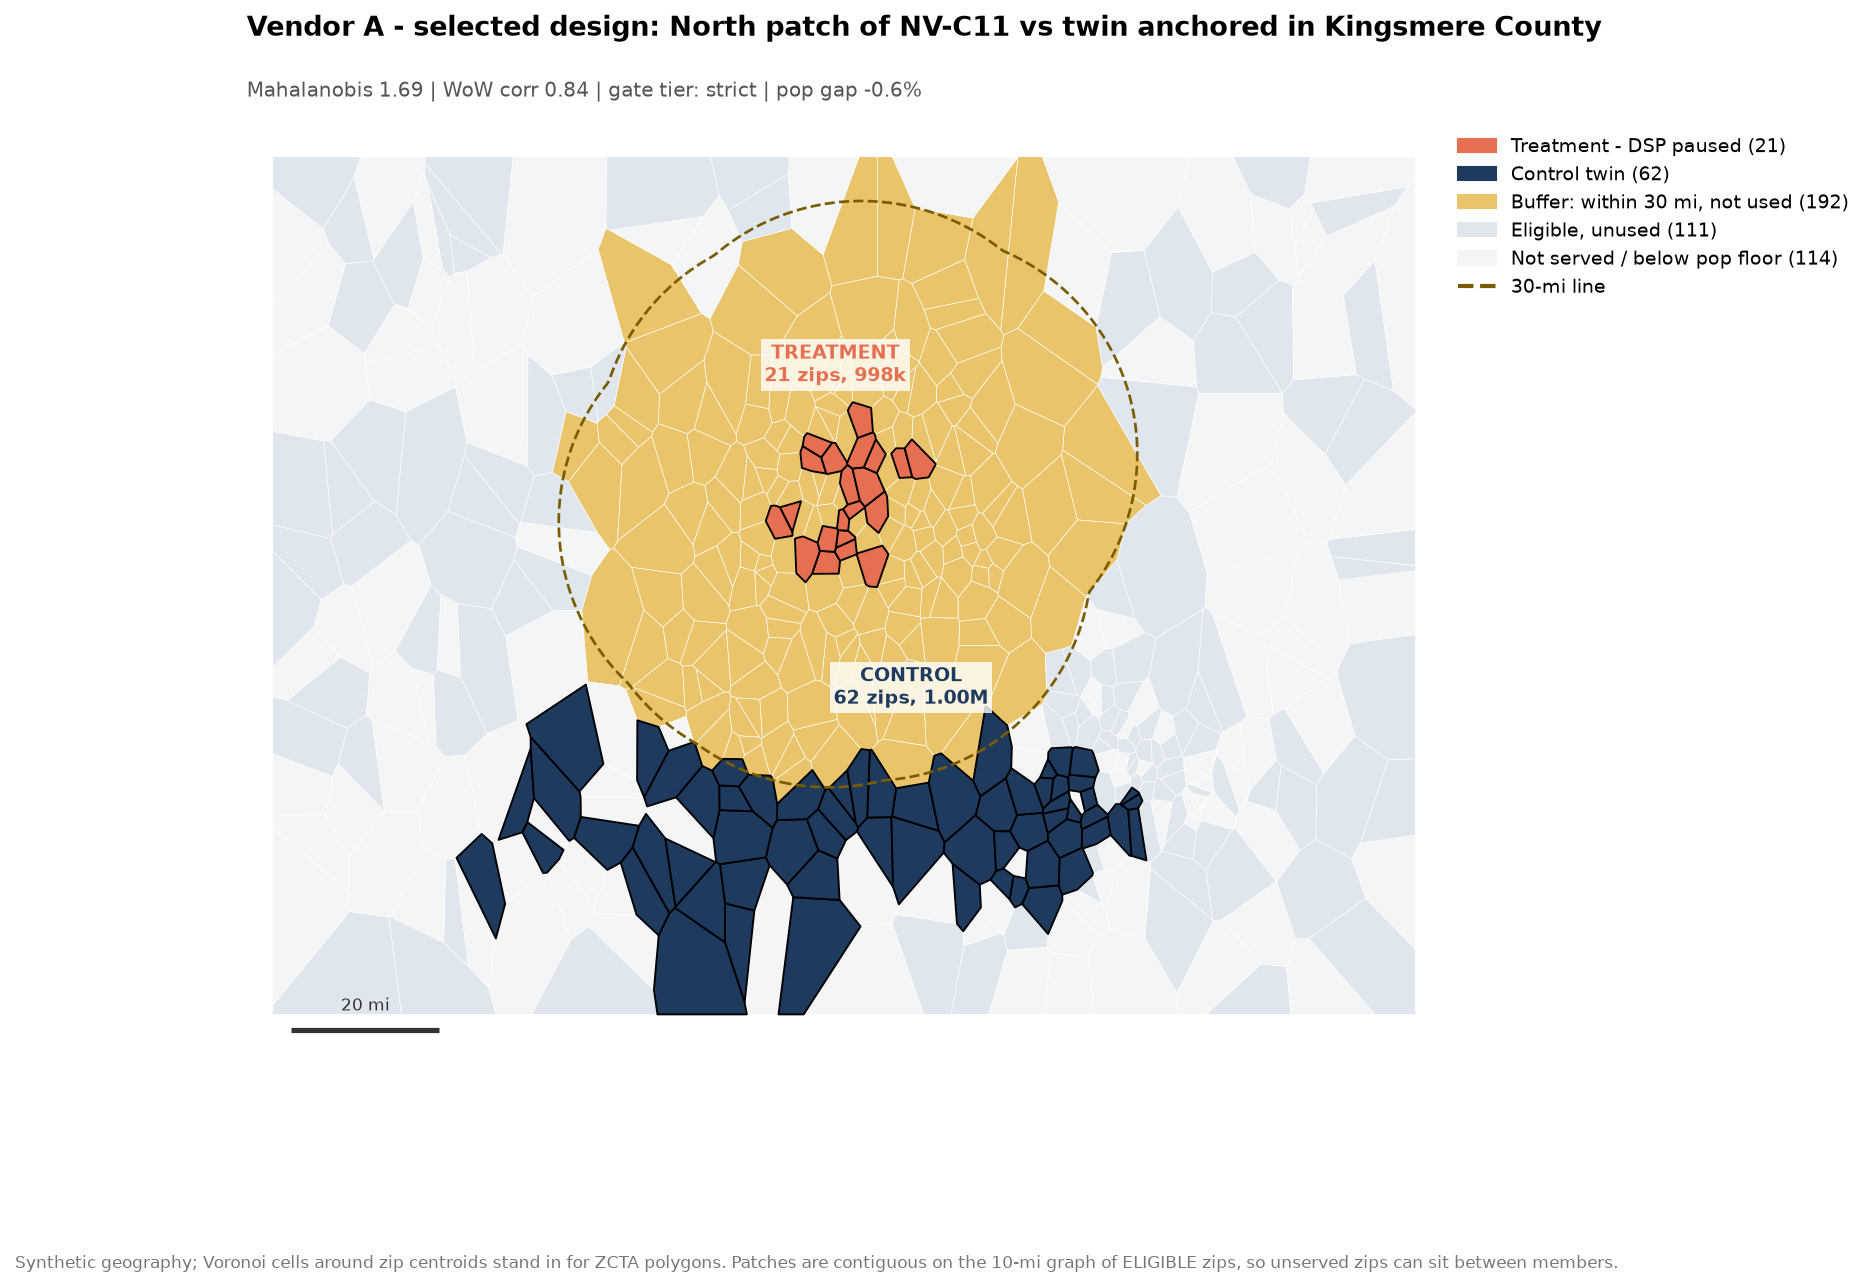

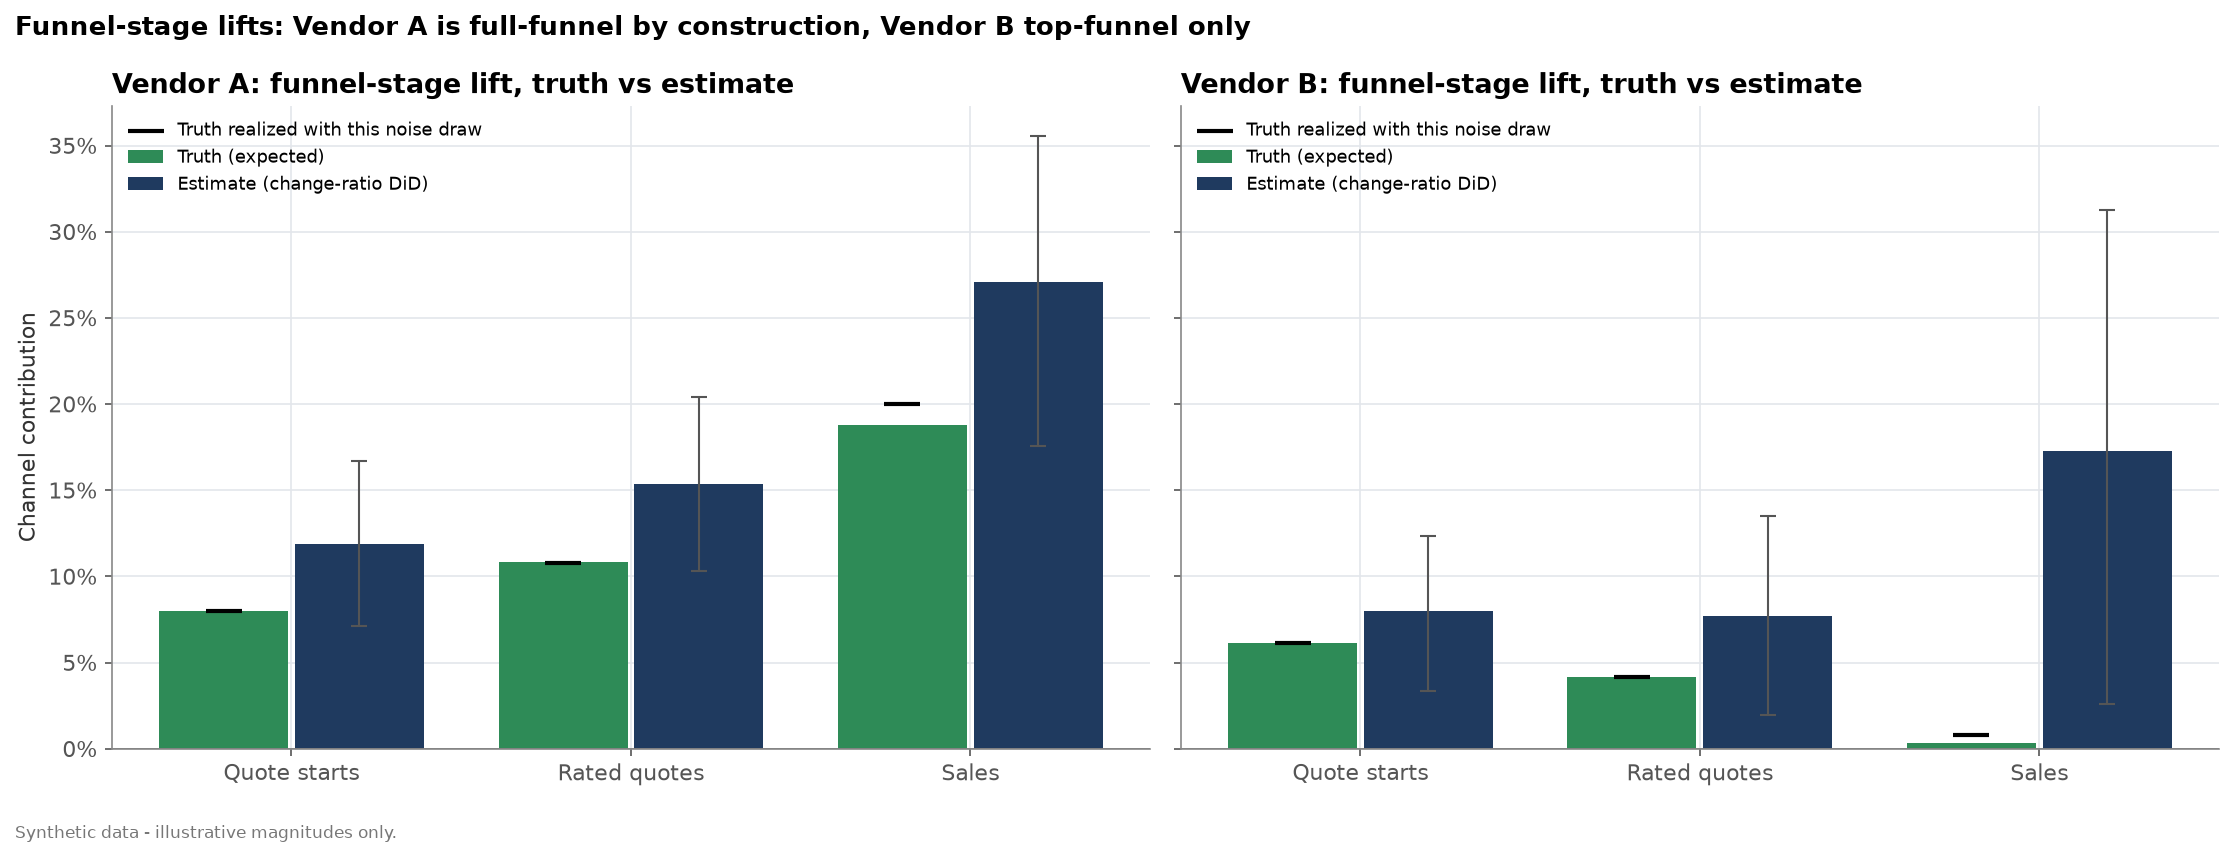

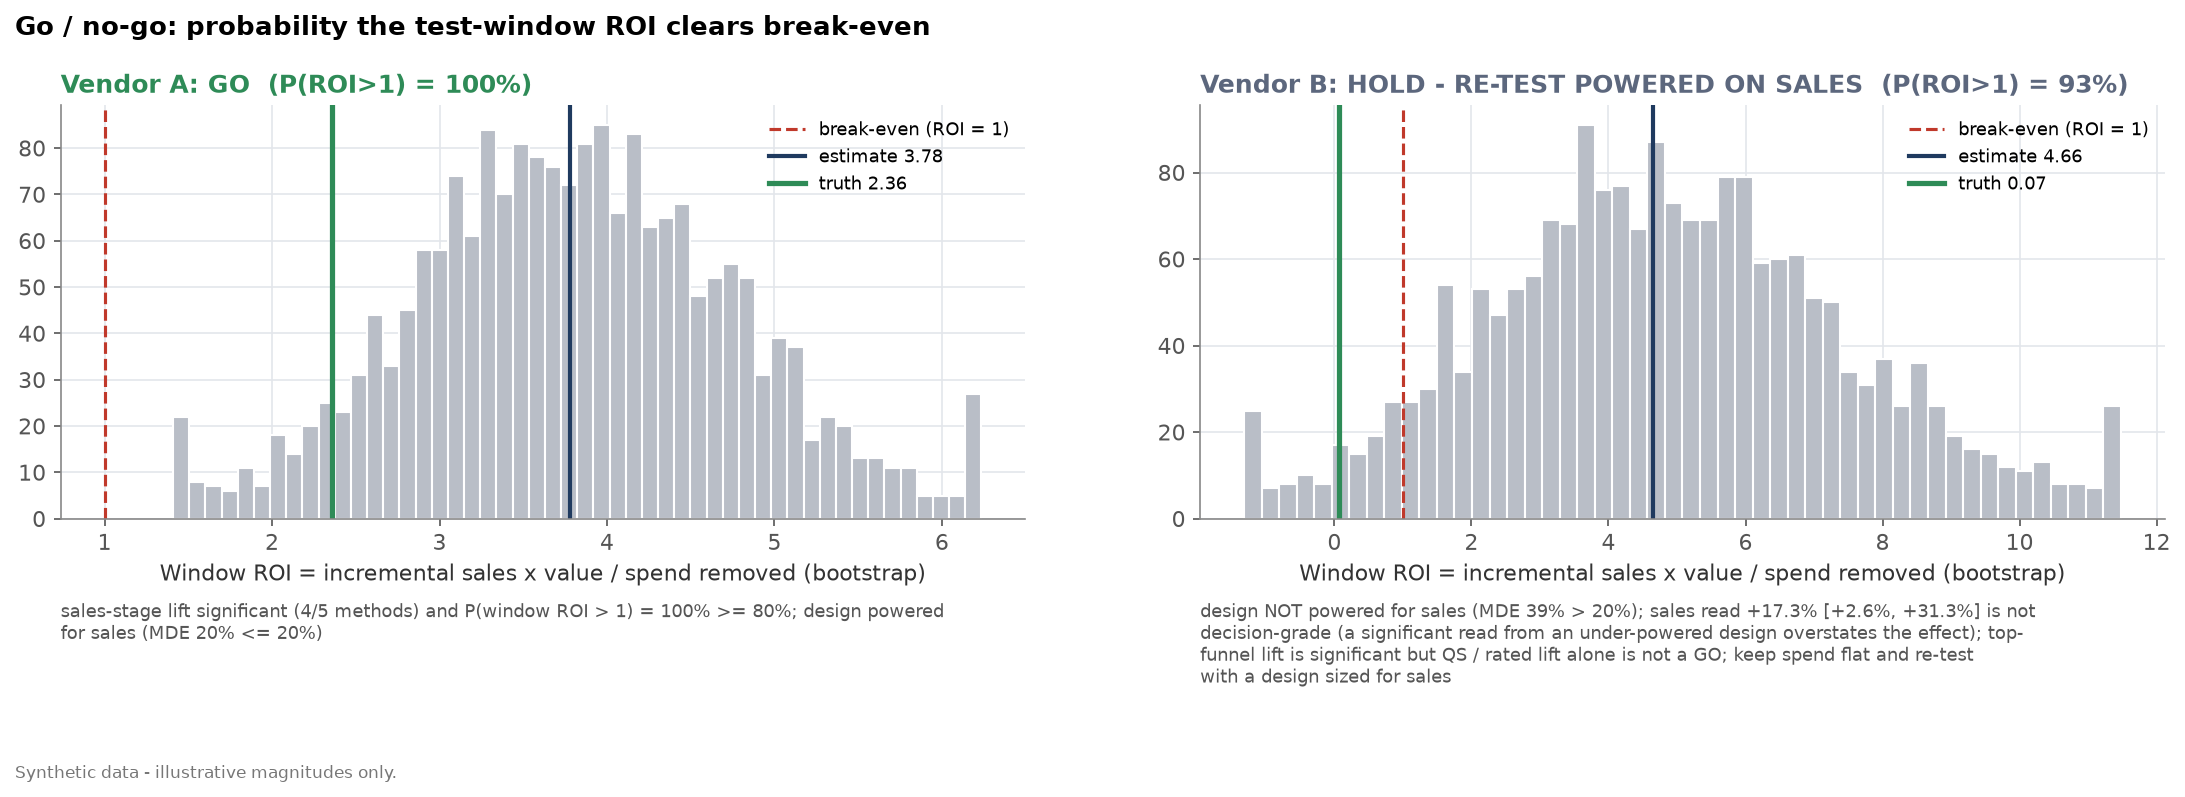

In [5]:
d = S["modules"]["dsp"]
lad = pd.DataFrame(R["dsp"]["design"]["dsp_a"]["sizing_ladder"])
display(lad[[c for c in lad.columns if c != "status"]].round(3))
display(Markdown(f"**Vendor A** - {d['a_sizing_verdict']}: {d['a_treated_pop']/1e6:.2f}M pop, {d['a_test_weeks']} weeks, "
                 f"design sales MDE {d['a_mde_sales_design']:.1%} -> **{d['a_decision']}** (window ROI {d['a_roi_est']:.2f}, "
                 f"true {d['a_roi_true']:.2f}).  \n**Vendor B** - design sales MDE {d['b_mde_sales_design']:.0%} -> "
                 f"**{d['b_decision']}** (true ROI {d['b_roi_true']:.2f}: its quote-start lift is real but it barely sells)."))
show("dsp", "08b_a_power_sizing_ladder")
show("dsp", "10_a_selected_design_map")
show("dsp", "24_readout_funnel_truth_vs_estimate")
show("dsp", "28_readout_roi_decision")

## 4 · The MMM gap: calibrate, then reallocate

Tests answer one question in one window in a few geos; budgeting needs a national, cross-channel, saturation-aware
answer. The Bayesian MMM (PyMC; geometric adstock + Hill per channel) is fit twice: without and with one lift-test
likelihood term per test arm (`observed incremental sales per $ ~ Normal(model-implied, SE)`).

,true,uncalibrated,calibrated,err uncal.,err cal.
tv,0.45,0.42,0.42,0.04,0.04
social,1.63,1.95,2.02,0.32,0.39
search_brand,1.79,1.41,1.43,0.38,0.36
search_nonbrand,1.26,0.97,0.85,0.30,0.41
dsp_a,3.89,3.39,3.44,0.50,0.45
dsp_b,0.08,0.68,0.72,0.60,0.64


Mean abs ROI error: uncalibrated **0.36** -> calibrated **0.38** with the tests as actually read; **0.36** if every test had been powered on sales (sensitivity using simulated truth-centred readouts).

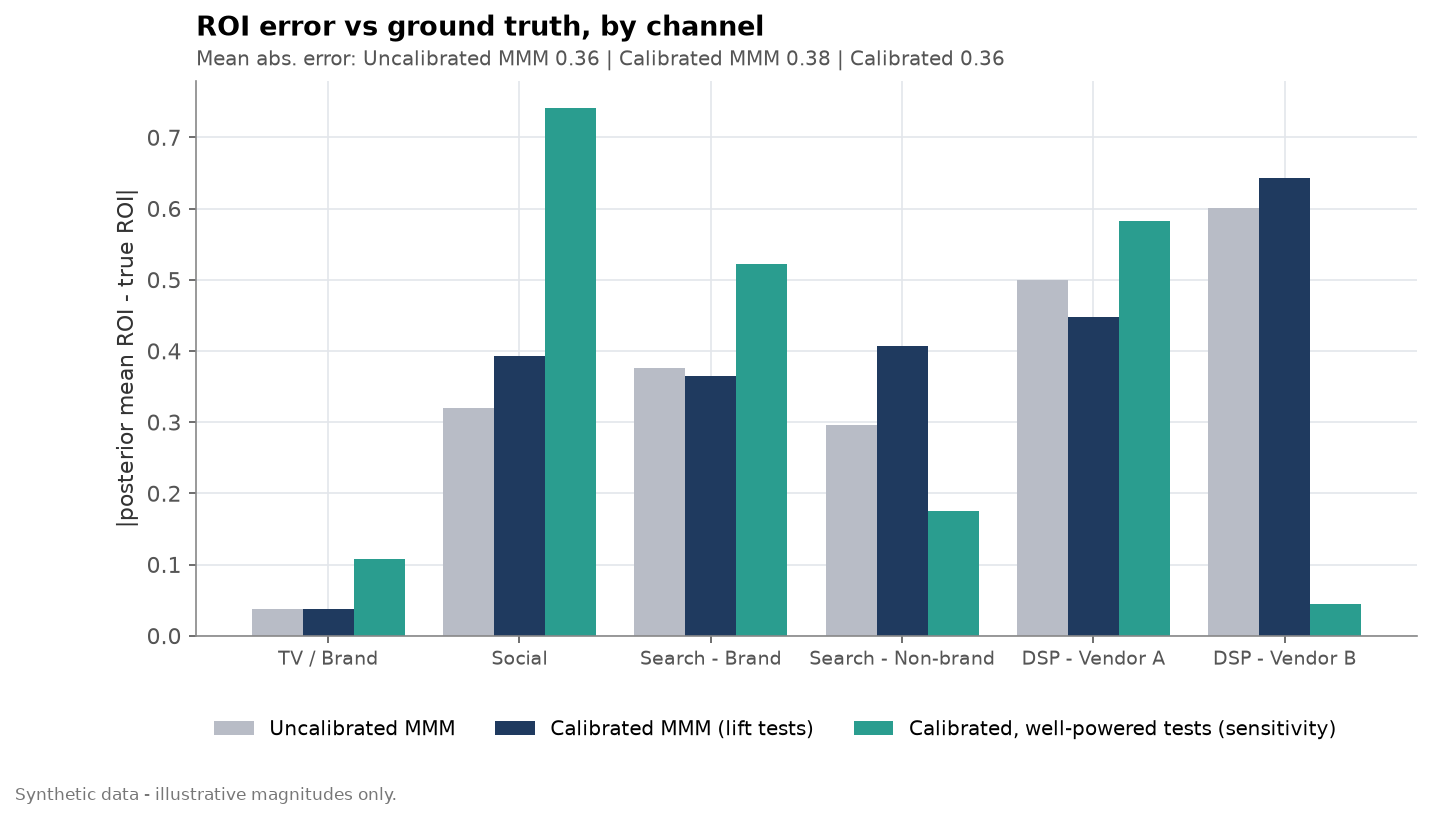

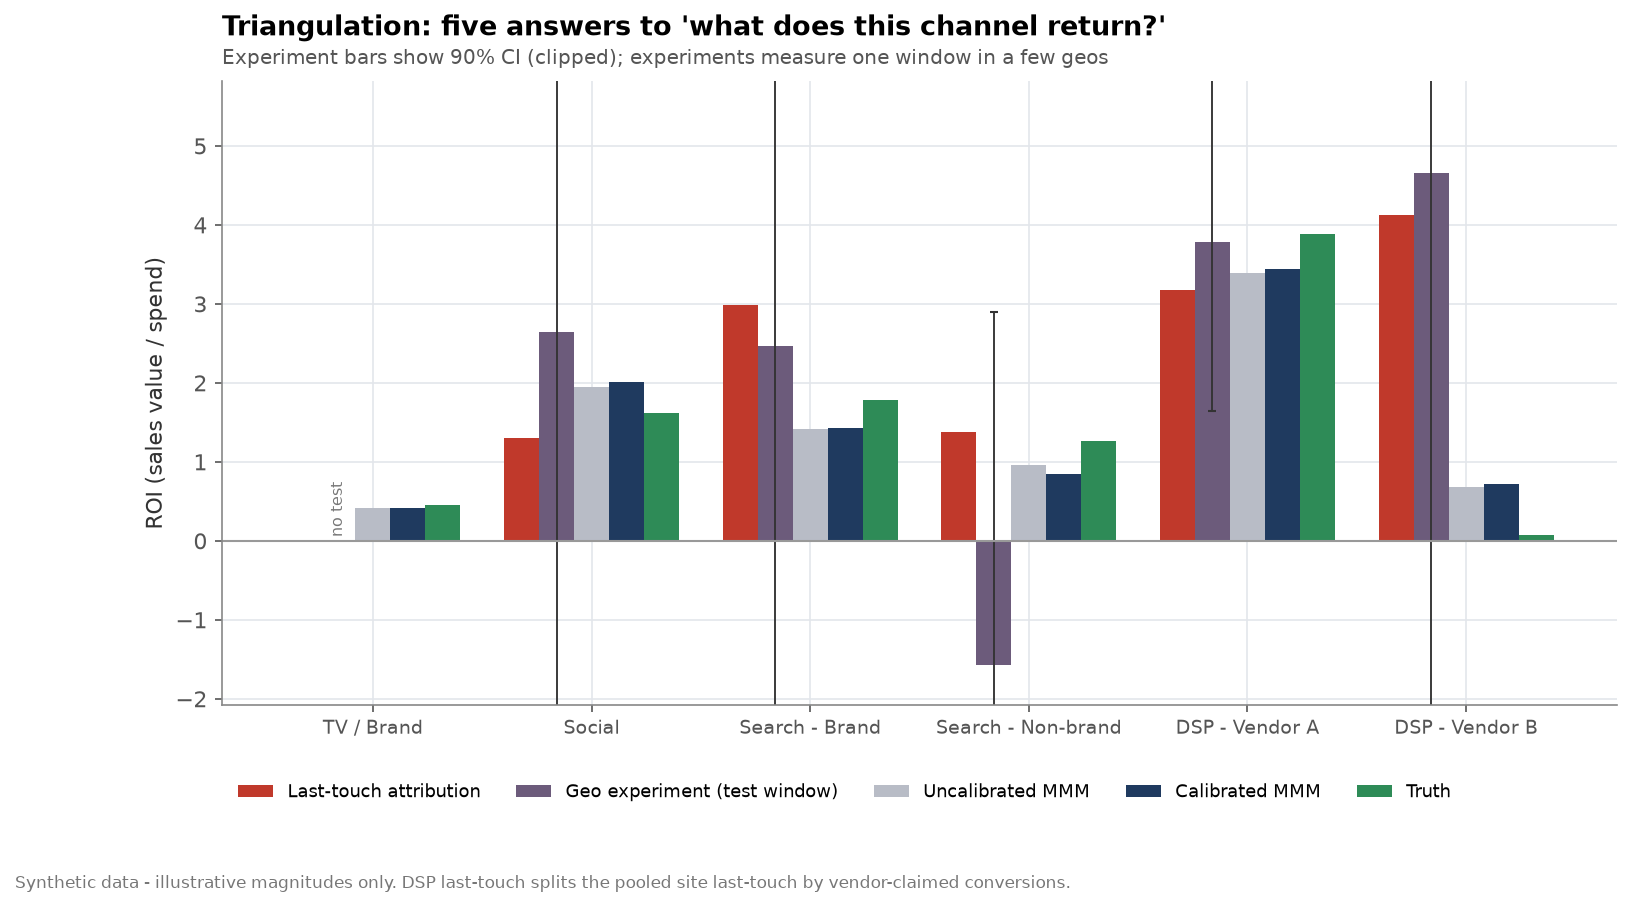

In [6]:
m = S["modules"]["mmm"]
roi = pd.DataFrame(m["roi_by_channel"]).T
roi["err uncal."] = (roi["uncalibrated"] - roi["true"]).abs()
roi["err cal."] = (roi["calibrated"] - roi["true"]).abs()
display(roi.round(2))
display(Markdown(f"Mean abs ROI error: uncalibrated **{m['roi_mae_uncalibrated']:.2f}** -> calibrated "
                 f"**{m['roi_mae_calibrated']:.2f}** with the tests as actually read; "
                 f"**{m['roi_mae_calibrated_powered_sensitivity']:.2f}** if every test had been powered on sales "
                 "(sensitivity using simulated truth-centred readouts)."))
show("mmm", "05_roi_error")
show("mmm", "11_triangulation")

**Reading it honestly.** Calibration is only as good as the tests feeding it. Four of five tests were powered on quote
starts, so their *sales* likelihood terms are weak and some point the wrong way; the one test designed for sales
(DSP Vendor A) pulls its channel toward the truth. Even with perfectly powered tests the gain is limited here, because a
12-week geo-local return at test spend only partly identifies a 3-year national ROI. That is the program's lesson, not a
footnote: power tests on the decision metric and design them to measure what the MMM needs.

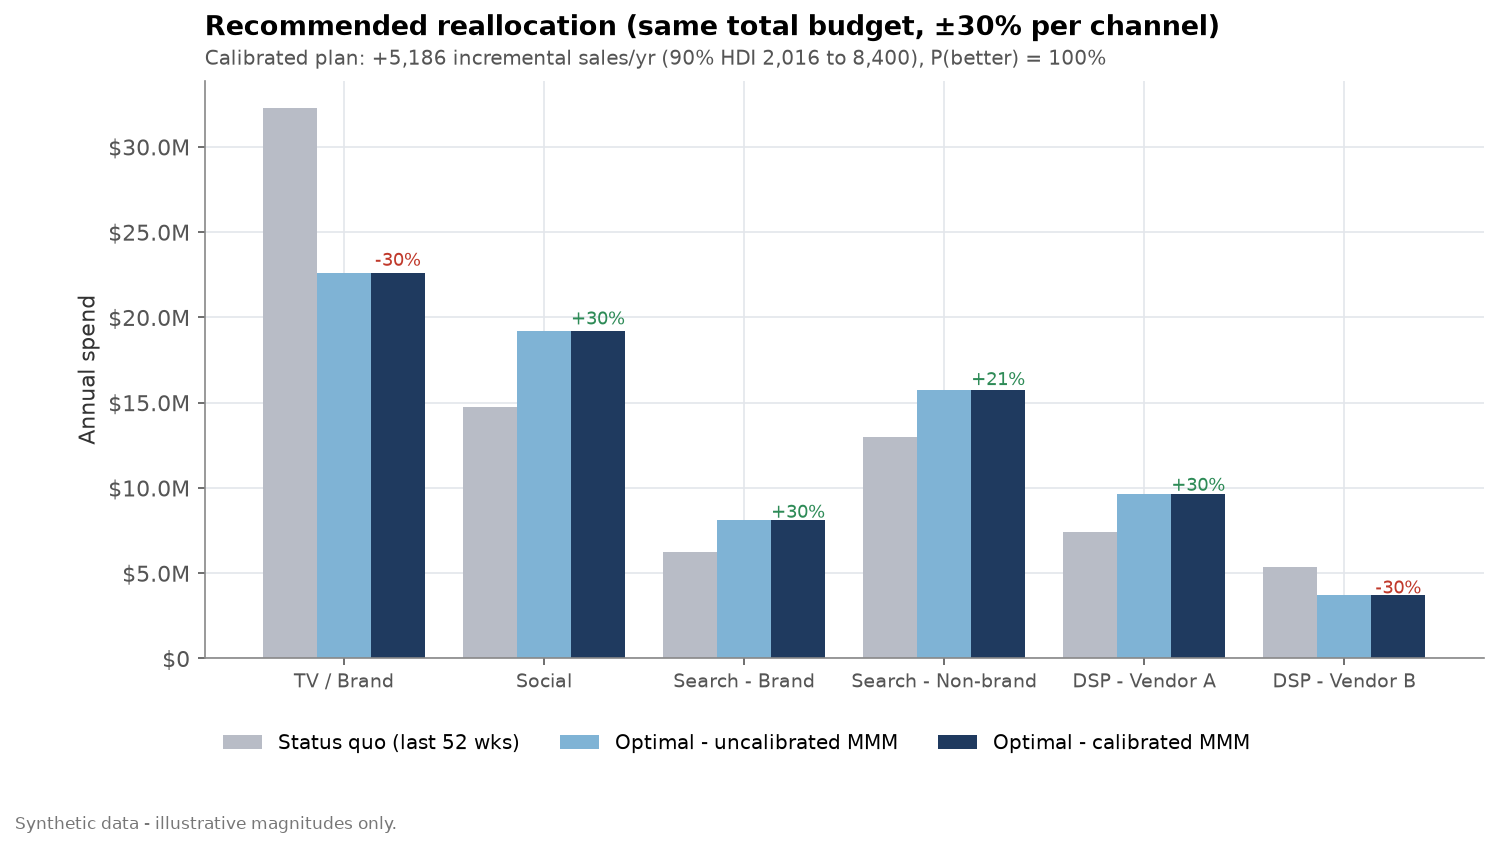

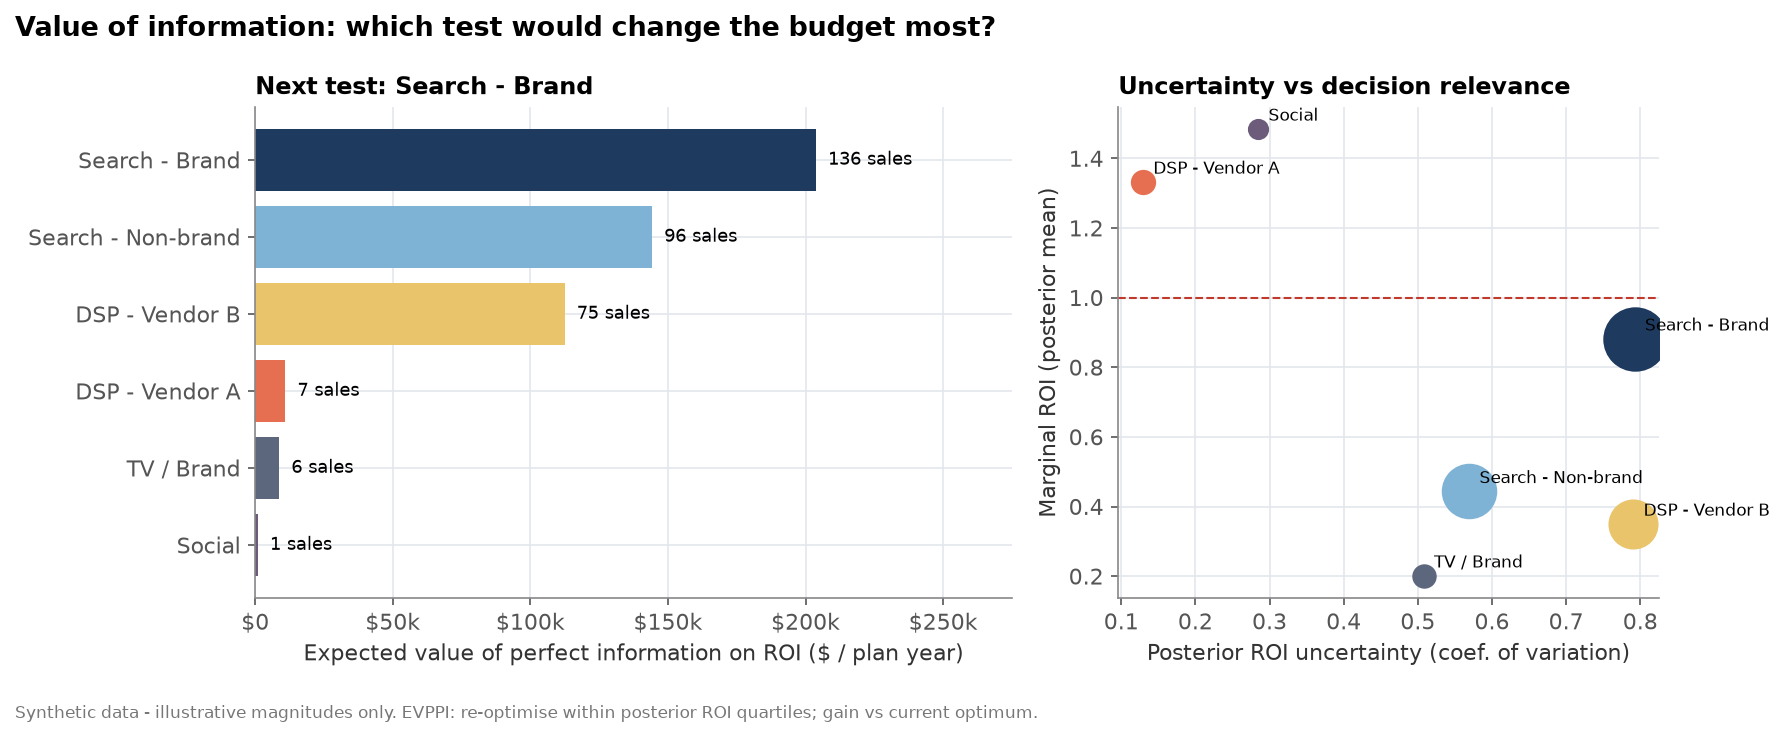

,tv,social,search_brand,search_nonbrand,dsp_a,dsp_b
spend multiplier,0.7,1.3,1.3,1.21,1.3,0.7


Same total budget, reallocated within +-30% per channel: **+6.9% true incremental sales** (checked against the simulator), cost per incremental sale $1,214 -> $1,126. **Next test: `search_brand`** (largest expected value of perfect information for the budget decision).

In [7]:
show("mmm", "12_optimizer_mix")
show("mmm", "15_value_of_information")
mult = pd.Series(m["optimizer_multipliers"]).rename("spend multiplier").round(2)
display(mult.to_frame().T)
display(Markdown(f"Same total budget, reallocated within +-30% per channel: **{m['optimizer_true_gain_pct']:+.1%} true "
                 f"incremental sales** (checked against the simulator), cost per incremental sale "
                 f"${m['cpa_status_quo']:,.0f} -> ${m['cpa_optimized']:,.0f}. **Next test: `{m['next_test']}`** "
                 "(largest expected value of perfect information for the budget decision)."))

## Scoreboard: every headline estimate vs the truth

In [8]:
sb = pd.DataFrame(S["scoreboard"])
sb[["test", "quantity", "estimate", "ci_low", "ci_high", "truth", "covers_truth"]].round(3)

,test,quantity,estimate,ci_low,ci_high,truth,covers_truth
0,Social holdout,Quote starts lift,0.027,-0.034,0.088,0.042,True
1,Social holdout,Sales lift,0.048,-0.086,0.182,0.047,True
2,Search dark-out,All paid search: rated-quote lift,0.091,0.002,0.180,0.093,True
3,Search dark-out,Branded only: rated-quote lift,0.098,-0.011,0.207,0.032,True
4,Search dark-out,Branded: organic recapture,0.345,0.108,0.628,0.400,True
5,DSP Vendor A,quote-start lift,0.119,0.071,0.167,0.080,True
6,DSP Vendor A,sales lift,0.271,0.176,0.355,0.188,True
7,DSP Vendor B,quote-start lift,0.080,0.034,0.123,0.061,True
8,DSP Vendor B,sales lift,0.173,0.026,0.313,0.003,False
9,MMM (calibrated),ROI tv,0.416,0.093,0.705,0.454,True


## What this program demonstrates

* **Design before readout.** Units are chosen by code from pre-period data (Mahalanobis matching, K-means + SC
  tournament, injected-lift validation, placebo inference), and the holdout size comes from a power analysis on the
  decision metric. Nothing is force-passed.
* **Triangulation.** Change-ratio DiD, two-way FE DiD with clustered SE, Welch on gaps, BSTS, synthetic control with
  placebo p-values and AugSynth-style correction - each scored against the truth.
* **Attribution is not incrementality.** Last-touch and vendor reports over- or under-claim by multiples.
* **Tests -> MMM -> budget.** Experiments calibrate the MMM; the MMM turns local test answers into a national
  reallocation and names the next test.

*Synthetic data. Magnitudes are illustrative and depend on the design and the noise draw.*